# T30. Validación temporal de las redes congeladas

**Objetivo.** Evaluar en la semana reservada las redes elegidas con los viajes del 1 al 21 de febrero. Comparar volumen, cobertura OD y P90 a toda Roma por geometría y repetir la prueba de T29 a pie en los dos núcleos. Los intervalos, radios y reglas son los mismos del ajuste. El conjunto de estaciones se conserva por huella.

In [1]:
import hashlib
import json
import pandas as pd
from IPython.display import display

from comun.config import cargar_config
from comun.datos import cargar_viajes
from comun.figuras import guardar_figura, plt
from comun.web import exportar
from peatones import META, evaluar, finalistas
from redes import (METODOS, OBJETIVO_PCT, RADIOS_PRINCIPALES, TABLAS, cobertura_split,
                   distancias, extremos, guardar, indicadores, leer)

info_t29 = json.loads((TABLAS / "T29_rutas_ajuste.json").read_text(encoding="utf-8"))
for nombre, huella in info_t29["seleccion"].items():
    if hashlib.sha256((TABLAS / nombre).read_bytes()).hexdigest() != huella:
        raise ValueError("La red de T28 cambió. Ejecuta T29 con la selección vigente.")

redes, estaciones = finalistas()
redes["prioridad"] = redes["rol"].map({"recomendada": 0, "menos_estaciones": 1, "radio_menor": 2})
redes = redes.sort_values("prioridad").drop(columns="prioridad")
periodos_cfg = cargar_config()["datos"]["periodos"]
geometria, diario, periodos = [], [], {}
for periodo, (inicio, fin) in periodos_cfg.items():
    viajes = cargar_viajes(periodo=periodo)
    n = len(viajes)
    dias = pd.date_range(inicio, fin, freq="D")
    periodos[periodo] = {"inicio": inicio, "fin": fin, "dias": len(dias), "viajes": n, "viajes_dia": n / len(dias)}
    fechas = viajes["tsO"].dt.strftime("%Y-%m-%d")
    for r in redes.itertuples():
        coords = estaciones.loc[estaciones["network_id"].eq(r.network_id), ["lon", "lat"]]
        d = distancias(extremos(viajes), coords).min(axis=1)
        m = indicadores(d, r.radio_m)
        geometria.append({"network_id": r.network_id, "periodo": periodo, "dias": len(dias),
                          "viajes_dia": n / len(dias), **m})
        _, _, ambos = cobertura_split(d, r.radio_m)
        serie = pd.DataFrame({"fecha": fechas, "cubiertos": ambos}).groupby("fecha")["cubiertos"].agg(["size", "sum"])
        serie = serie.reindex(dias.strftime("%Y-%m-%d"), fill_value=0).rename_axis("fecha").reset_index()
        diario.append(serie.rename(columns={"size": "viajes", "sum": "viajes_cubiertos"})
                      .assign(periodo=periodo, network_id=r.network_id))

geo = pd.DataFrame(geometria)
ajuste_geo = geo.loc[geo["periodo"].eq("ajuste")].set_index("network_id")["viajes_cubiertos"]
assert (redes.set_index("network_id")["viajes_cubiertos"] == ajuste_geo.reindex(redes["network_id"])).all()
guardada = pd.concat(diario, ignore_index=True)
guardar(geo, "T30_validacion_geometrica")
guardar(guardada, "T30_cobertura_diaria")

muestra_reservada, control, ejemplos_reservados = evaluar("reservada", redes, estaciones)
en_pie = pd.concat([leer("T29_cobertura_peatonal"), muestra_reservada], ignore_index=True)
guardar(en_pie, "T30_validacion_peatonal")
guardar(control, "T30_grafo_reservada")
display(geo[["network_id", "periodo", "viajes", "viajes_cubiertos", "pct_viajes_cubiertos", "d_p90_m"]].round(2))
display(muestra_reservada[["network_id", "sector", "viajes_comparables", "viajes_sin_par_rutas",
                          "pct_linea", "pct_a_pie", "delta_pp"]].round(2))

,network_id,periodo,viajes,viajes_cubiertos,pct_viajes_cubiertos,d_p90_m
0,lscp_r300_k159,ajuste,16710,13373,80.03,309.78
1,mclp_r300_k158,ajuste,16710,13334,79.80,310.43
2,lscp_r250_k225,ajuste,16710,13374,80.04,265.65
3,lscp_r300_k159,reservada,6582,4977,75.62,329.39
4,mclp_r300_k158,reservada,6582,4973,75.55,329.56
5,lscp_r250_k225,reservada,6582,4926,74.84,292.29


,network_id,sector,viajes_comparables,viajes_sin_par_rutas,pct_linea,pct_a_pie,delta_pp
0,lscp_r300_k159,tiber,246,2,86.99,54.07,-32.93
1,mclp_r300_k158,tiber,246,2,86.99,54.07,-32.93
2,lscp_r250_k225,tiber,246,2,89.84,47.15,-42.68
3,lscp_r300_k159,termini,181,0,75.69,30.39,-45.30
4,mclp_r300_k158,termini,181,0,75.69,30.39,-45.30
5,lscp_r250_k225,termini,181,0,71.27,43.65,-27.62
6,lscp_r300_k159,ambos,427,2,82.20,44.03,-38.17
7,mclp_r300_k158,ambos,427,2,82.20,44.03,-38.17
8,lscp_r250_k225,ambos,427,2,81.97,45.67,-36.30


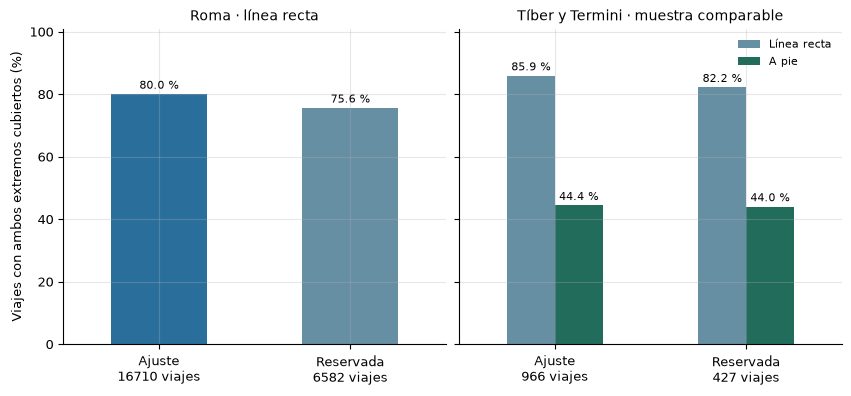

In [2]:
principal = redes.iloc[0]
principal_id = principal["network_id"]
r = geo.loc[geo["network_id"].eq(principal_id)].set_index("periodo").loc[["ajuste", "reservada"]]
p = en_pie.loc[en_pie["network_id"].eq(principal_id) & en_pie["sector"].eq("ambos")].set_index("periodo").loc[
    ["ajuste", "reservada"]
]
fig, axes = plt.subplots(1, 2, figsize=(8.4, 3.85), sharey=True, layout="constrained")
r["pct_viajes_cubiertos"].plot.bar(ax=axes[0], color=["#2a6f9b", "#678fa4"], rot=0)
axes[0].bar_label(axes[0].containers[0], fmt="%.1f %%", padding=2, fontsize=8)
axes[0].set_xticklabels([f"Ajuste\n{r.loc['ajuste','viajes']} viajes", f"Reservada\n{r.loc['reservada','viajes']} viajes"])
axes[0].set(ylabel="Viajes con ambos extremos cubiertos (%)", title="Roma · línea recta", ylim=(0, 101), xlabel="")
p[["pct_linea", "pct_a_pie"]].plot.bar(ax=axes[1], color=["#678fa4", "#226c5b"], rot=0)
for barra in axes[1].containers:
    axes[1].bar_label(barra, fmt="%.1f %%", padding=2, fontsize=8)
axes[1].set_xticklabels([f"Ajuste\n{p.loc['ajuste','viajes_comparables']} viajes", f"Reservada\n{p.loc['reservada','viajes_comparables']} viajes"])
axes[1].set(title="Tíber y Termini · muestra comparable", xlabel="")
axes[1].legend(["Línea recta", "A pie"], frameon=False)
guardar_figura(fig, "movilidad", "T30_validacion")

meta = json.loads(META.read_text(encoding="utf-8"))
sectores = [{"id": k, "nombre": v["nombre"], "nucleo": v["nucleo"],
             "recorte": v["recorte"], "fuentes": [{"url": f["fuente"], "fecha": f["snapshot"]} for f in v["ficheros"]]}
            for k, v in meta["sectores"].items()]
redes_web = redes[["network_id", "rol", "metodo", "radio_m", "k", "estaciones"]]
comp = leer("T28_comparacion")
cols_solver = ["network_id", "metodo", "k", "radio_m", "pct_viajes_cubiertos", "obj_factible",
               "estado_solver", "origen_solucion", "fuente_cota", "cota_obj", "brecha_pct", "solver_s", "optimalidad_probada"]
exportar("fase1", "t30_validacion_red", {
    "seleccionada": principal_id, "objetivo_pct": OBJETIVO_PCT, "radios_principales": RADIOS_PRINCIPALES,
    "huella_redes": info_t29["seleccion"]["T28_estaciones.csv"], "periodos": periodos, "metodos": METODOS,
    "redes": redes_web, "geometria": geo, "peatonal": en_pie, "sectores": sectores,
    "ejemplos": [*info_t29["ejemplos"], *ejemplos_reservados],
    "barrido": comp, "lscp": leer("T26_resultados")[cols_solver],
    "solver": leer("T27_resultados").loc[lambda t: t["metodo"].ne("voraz"), cols_solver],
})

**Lectura.** La comparación global usa todas las salidas elegibles de cada periodo. En la prueba a pie se compara sobre pares de rutas medibles en los dos sectores. La ficha web publica el denominador, los casos sin par de rutas y ejemplos de un tramo peatonal observado como extremo de viaje. Los resultados calculan acceso a una red propuesta, previo a la simulación de inventario.